# Interpretability analyses of the frozen cross-session EEGNet models

This notebook analyses the models that were **already trained and frozen** by `cross_session_eegnet.ipynb`. It loads the saved best-validation checkpoints; **nothing is retrained and no hyper-parameter, seed or preprocessing choice is changed.**



## Pre-specified plan

| # | Analysis | Question it can answer | What it cannot show |
|---|---|---|---|
| 1 | **Frequency perturbation**: remove mu (8–12 Hz), beta (13–30 Hz) or mu+beta (8–30 Hz) from every test window and measure the change in balanced accuracy, against control bands | does the trained model's output depend on these frequencies *more than on control frequencies*? | that the model uses *oscillatory ERD/ERS* specifically; it shows dependence on spectral content |
| 1b | **Variant B of analysis 1** (added after variant A was seen, see section 2b): the same removal applied to baseline and window *before* the baseline normalisation | whether the dependence survives when the perturbation does not create an artificial class-independent amplitude drop | same limits as analysis 1 |
| 2 | **Channel occlusion**: set C3/Cz/C4, or all sensorimotor channels, to the pre-cue baseline value (0 in normalised units) and compare with control channel groups and with random channel subsets | does the decision depend on the expected scalp areas? | which brain sources are used (EEG channels mix sources) |
| 3 | **ERD/ERS maps per class**: band power relative to the pre-cue baseline, from the cleaned data, independent of the model | do the data contain the expected effect (contralateral mu/beta decrease)? | anything about what EEGNet does |
| 4 | **Class-by-class comparison**: per-class recall and confusions of the frozen models next to the ERD of step 3 | are the confusion patterns compatible with the lateralisation seen in the data? | a causal link; it is an interpretation, not a test |

**Fixed definitions.** Frequency bands are removed with an FFT band-stop on each baseline-normalised 3 s window (analysis-only and non-causal by construction; resolution ≈ 0.33 Hz). Controls: for mu (4 Hz wide) 2–6, 32–36 and 36–40 Hz, all 4 Hz wide; for beta (17 Hz wide) 2–8 plus 31–40 Hz (15 Hz in total, *not* exactly matched); for mu+beta (22 Hz wide) all remaining frequencies 1.5–7.9 plus 30.1–40 Hz (≈17 Hz, narrower). Because exact width matching is impossible outside 8–30 Hz, the table also reports the **bandwidth and the fraction of window variance removed** by every perturbation, so that dose can be compared. Channel groups: core = C3, Cz, C4; sensorimotor = FC3, FC1, FCz, FC2, FC4, C5, C3, C1, Cz, C2, C4, C6, CP3, CP1, CPz, CP2, CP4 (17 channels); the only non-sensorimotor channels are Fz, P1, Pz, P2, POz (5). Random control subsets have the same size as the target group (200 draws, fixed seed). Uncertainty: a trial-level paired bootstrap (1000 resamples, fixed seed) of the change in balanced accuracy; it reflects trial sampling within one participant and session only, not variability across sessions or participants.

**Pre-specified descriptive reading rule (not a significance test).** A band is described as "the model output depends on it more than on its controls" for a participant/model only if removing it reduces balanced accuracy by more than removing **each** of its controls. The rule is permissive when the changes are close to zero, so the tables also report whether the bootstrap interval of the target drop excludes 0 (`target_ci_excludes_zero`); this column was added for reading the rule and does not change it. A channel group is described as "more important than chance subsets" only if its drop is at least as large as that of the vast majority of random subsets of equal size (the percentile is reported, no threshold is used for a decision).

**Distribution-shift check.** Every perturbation also reports `max_pred_class_share`, the fraction of test predictions assigned to the single most frequent class (0.25-0.30 means predictions stay spread over the classes; values near 1 mean the model collapses to one class, which points to input distribution shift rather than selective loss of information).

**Caveats.** Removing a band also changes the signal scale and creates inputs the model never saw, so any drop partly reflects distribution shift; that is why controls are mandatory. Beta may contain muscle activity, which the 1–40 Hz filter reduces but does not exclude. With few participants and one seed, all results are descriptive. No claim about "mu/beta rhythms" is made beyond what the controls support.

In [ ]:
import os, json, time, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import tensorflow as tf
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import balanced_accuracy_score, recall_score
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Dense, Activation, Dropout, Conv2D, AveragePooling2D,
                                     SeparableConv2D, DepthwiseConv2D, BatchNormalization, Flatten, Input)
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam

mne.set_log_level('WARNING')

# ---------------- locate the frozen experiment ----------------
RESULTS_DIR = Path(os.environ.get('BCI_OUT_DIR', 'results_cross_session')) / 'full'
FROZEN = json.loads((RESULTS_DIR / 'frozen_experiment_config.json').read_text())
CFG = FROZEN['cfg']                                                   # the configuration that was frozen before the experiment
CFG['bci_code_to_label'] = {int(k): v for k, v in CFG['bci_code_to_label'].items()}   # JSON turns the keys into strings
if os.environ.get('BCI_CLEAN_DIR'):                                   # optional override of the cleaned-data location
    CFG['clean_dir'] = str(Path(os.environ['BCI_CLEAN_DIR']) / CFG['ica_source_E'])
SUBJECTS = [int(x) for x in os.environ['BCI_SUBJECTS'].split(',')] if os.environ.get('BCI_SUBJECTS') else FROZEN['subjects_run']
CONDITIONS, SEEDS = FROZEN['conditions'], FROZEN['seeds']
FS = CFG['fs']
CH = CFG['expected_ch_names']
ix = {c: i for i, c in enumerate(CH)}                 # channel name -> index

# ---------------- analysis constants: fixed in the plan above, NOT tuned ----------------
N_RANDOM_SUBSETS = 200
N_BOOT = 1000
RNG_SEED = 12345
OUT = RESULTS_DIR / 'interpretability'
OUT.mkdir(parents=True, exist_ok=True)
print('frozen configuration hash:', FROZEN['cfg_hash'], '| participants:', SUBJECTS, '| conditions:', CONDITIONS, '| seeds:', SEEDS)
print('cleaned data:', CFG['clean_dir'], '| outputs:', OUT)

frozen configuration hash: b9a8e7bf09f96cb6 | participants: [1, 2, 3, 4, 5, 6, 7, 8, 9] | conditions: ['NoAug', 'Aug'] | seeds: [0]
cleaned data: cleaned_data_1_40_runwise\own_calibration | outputs: results_cross_session\full\interpretability


## 1. Loading the frozen models and the test windows

The functions below are copied **verbatim** from `cross_session_eegnet.ipynb` (EEGNet definition, trial table, provenance check, windowing and baseline normalisation), so the test inputs and the architecture are built by identical code. The checkpoint of each model is the best-validation checkpoint written by that fit.

**Reproduction check.** Before any perturbation, every loaded model must reproduce the predictions that were saved by the main experiment (same trials, same predicted labels). If it does not, the notebook stops.

In [2]:
EVENT_DESC = {1: 'left', 2: 'right', 3: 'foot', 4: 'tongue'}

DESC_TO_LABEL = {'left': 0, 'right': 1, 'foot': 2, 'tongue': 3}

def session_paths(sid, session):
    """session: 'T' (first session) or 'E' (second session). All files come from the preprocessing notebook."""
    name = f'A{sid:02d}{session}'
    clean = Path(CFG['clean_dir'])
    return dict(
        name=name,
        fif=clean / f"{name}{CFG['clean_suffix']}",
        trials=clean / f'{name}_trials.csv',
        provenance=clean / f'{name}_provenance.json',
    )

def read_trial_table(p):
    """Trial table written by the preprocessing notebook: one row per trial, cue position, run, label, artifact flag."""
    df = pd.read_csv(p['trials'])
    assert len(df) == 288 and df['label_code'].isin([1, 2, 3, 4]).all()
    assert {'run', 'cue_sample', 'trial_start_sample', 'run_start_sample', 'run_end_sample'} <= set(df.columns)
    assert sorted(df['run'].unique()) == list(range(6)) and (df.groupby('run').size() == 48).all(), 'expected 6 task runs of 48 trials'
    assert (df['cue_sample'] - df['trial_start_sample'] == 500).all(), 'cue is not 500 samples after the trial start'
    df['label'] = df['label_code'].map(CFG['bci_code_to_label'])      # explicit mapping 1..4 -> 0..3
    assert df['label'].notna().all()
    return df

def check_provenance(p, session):
    """Refuse cleaned files produced by a different pipeline version or configuration."""
    if not Path(p['provenance']).exists():
        raise FileNotFoundError(f"{p['provenance']} not found: run 6_preprocessing_both_sessions.ipynb with the same "
                                f"ica_source_E setting ({CFG['ica_source_E']}); files from other pipelines are not accepted.")
    prov = json.loads(Path(p['provenance']).read_text())
    fp = prov['fingerprint']
    assert prov['pipeline_version'] == CFG['pipeline_version'], 'cleaned file comes from a different pipeline version'
    assert prov['session'] == session
    assert fp['ica_source_E_setting'] == CFG['ica_source_E'], 'files were produced with a different ica_source_E setting'
    assert tuple(fp['band_hz']) == tuple(CFG['band_hz']) and prov['filter']['phase'] == 'minimum'
    assert prov['calibration_events_verified'] is True
    assert prov['ica']['uses_task_runs_for_fit'] is False and prov['ica']['uses_labels'] is False
    return prov

def read_clean_eeg(fif_path):
    raw = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)
    ann = raw.annotations
    ev_mask = np.isin(ann.description, list(DESC_TO_LABEL))
    ann_samples = np.round(ann.onset[ev_mask] * raw.info['sfreq']).astype(int)
    ann_desc = np.asarray(ann.description)[ev_mask]
    raw.pick(['eeg'])                                           # drops the 3 EOG channels
    assert raw.ch_names == CFG['expected_ch_names'], f'Unexpected channel order: {raw.ch_names}'
    assert int(raw.info['sfreq']) == CFG['fs']
    return raw.get_data().astype(np.float64), ann_samples, ann_desc

def load_session(sid, session):
    """Epoch one session. Returns (X, y, meta) with X: (n_kept, 22, n_samples, 1).
    The window is defined relative to the CUE; labels are returned separately and are never part of X."""
    p = session_paths(sid, session)
    check_provenance(p, session)                                # refuse files made with a different pipeline/configuration
    meta = read_trial_table(p)
    assert (meta['session'] == session).all()
    eeg, ann_samples, ann_desc = read_clean_eeg(p['fif'])
    assert np.isfinite(eeg).all(), 'NaN/inf in the cleaned recording'

    # 1) cue annotations of the cleaned file must coincide with the trial table (same samples, same classes)
    order = np.argsort(ann_samples)
    ann_samples, ann_desc = ann_samples[order], ann_desc[order]
    assert np.array_equal(ann_samples, np.sort(meta['cue_sample'].values)), 'cue positions differ between .fif and trial table'
    assert np.array_equal(np.array([DESC_TO_LABEL[d] for d in ann_desc]),
                          meta.sort_values('cue_sample')['label'].values), 'labels differ between .fif and trial table'

    # 2) windowing relative to the cue
    fs = CFG['fs']
    start_off = int(round(CFG['mi_start_after_cue_s'] * fs))
    n_samp = CFG['n_samples']
    b0, b1 = int(round(CFG['baseline_start_s'] * fs)), int(round(CFG['baseline_end_s'] * fs))
    # the baseline must end at/before the cue and before the classification window starts
    assert CFG['baseline_end_s'] <= 0 and CFG['baseline_end_s'] <= CFG['mi_start_after_cue_s']
    # every baseline and window must lie INSIDE the correct run (run boundaries come from the trial table)
    assert (meta['cue_sample'] + b0 >= meta['run_start_sample']).all(), 'a baseline starts before its run'
    assert (meta['cue_sample'] + start_off + n_samp <= meta['run_end_sample']).all(), 'a window extends past its run'
    assert meta['run_end_sample'].max() <= eeg.shape[1]
    keep, reason, segs = [], [], []
    for cue in meta['cue_sample'].values:
        s0 = cue + start_off
        seg = eeg[:, s0:s0 + n_samp]
        base = eeg[:, cue + b0:cue + b1]                        # pre-cue fixation period (precedes the window)
        assert seg.shape[1] == n_samp and np.isfinite(seg).all() and np.isfinite(base).all()
        if (seg.std(axis=-1) < 1e-12).any() or (base.std(axis=-1) < 1e-12).any():
            keep.append(False); reason.append('flat channel'); continue
        if CFG['normalization'] == 'baseline_pre_cue':
            # per-channel mean/std come ONLY from samples that precede the classification window
            seg = (seg - base.mean(axis=-1, keepdims=True)) / (base.std(axis=-1, keepdims=True) + 1e-8)
        elif CFG['normalization'] == 'trial_zscore':
            # legacy: statistics of the whole window (includes its own later samples); exploratory only
            seg = (seg - seg.mean(axis=-1, keepdims=True)) / (seg.std(axis=-1, keepdims=True) + 1e-8)
        else:
            raise ValueError(CFG['normalization'])
        assert np.isfinite(seg).all()
        keep.append(True); reason.append(''); segs.append(seg)
    meta['kept'], meta['exclusion_reason'] = keep, reason
    meta['subject'], meta['session'] = sid, session
    meta['trial_id'] = [f'A{sid:02d}{session}_{i:03d}' for i in meta['trial_in_session']]

    X = np.stack(segs).astype(np.float32)
    assert np.isfinite(X).all()
    y = meta.loc[meta['kept'], 'label'].values.astype(np.int64)    # labels are returned separately: never part of X
    return X[..., np.newaxis], y, meta

def EEGNet_Model(nb_classes, Chans, Samples, dropoutRate=0.5):
    input1 = Input(shape=(Chans, Samples, 1))
    block1 = Conv2D(8, (1, 64), padding='same', use_bias=False)(input1)
    block1 = BatchNormalization()(block1)
    block1 = DepthwiseConv2D((Chans, 1), use_bias=False, depth_multiplier=2,
                             depthwise_constraint=max_norm(1.))(block1)
    block1 = BatchNormalization()(block1)
    block1 = Activation('elu')(block1)
    block1 = AveragePooling2D((1, 4))(block1)
    block1 = Dropout(dropoutRate)(block1)
    block2 = SeparableConv2D(16, (1, 16), use_bias=False, padding='same')(block1)
    block2 = BatchNormalization()(block2)
    block2 = Activation('elu')(block2)
    block2 = AveragePooling2D((1, 8))(block2)
    block2 = Dropout(dropoutRate)(block2)
    flatten = Flatten()(block2)
    dense = Dense(nb_classes, kernel_constraint=max_norm(0.25))(flatten)
    return Model(inputs=input1, outputs=Activation('softmax')(dense))

def build_model(chans, samples):
    m = EEGNet_Model(nb_classes=len(CFG['class_names']), Chans=chans, Samples=samples, dropoutRate=CFG['dropout'])
    m.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=CFG['learning_rate']),
              metrics=['accuracy'])
    return m

In [3]:
def load_model(sid, cond, seed):
    rid = f'A{sid:02d}_{cond}_seed{seed}'
    ckpt = RESULTS_DIR / 'checkpoints_final' / f'{rid}.weights.h5'
    assert ckpt.exists(), f'missing checkpoint {ckpt}'
    tf.keras.backend.clear_session()
    model = build_model(CFG['n_channels'], CFG['n_samples'])          # same architecture as in the main experiment
    model.load_weights(str(ckpt))
    return model, rid

def predict_labels(model, X3):
    return model.predict(X3[..., None], batch_size=len(X3), verbose=0).argmax(axis=1)

def bal_acc(y, p):
    return float(balanced_accuracy_score(y, p))

DATA = {}            # participant -> (X test windows (n, 22, 751), labels, trial table)
repro = []
for sid in SUBJECTS:
    Xe, ye, me = load_session(sid, 'E')                              # session E windows, baseline-normalised exactly as in the main run
    DATA[sid] = (Xe[..., 0], ye, me)
    kept_ids = me.loc[me['kept'], 'trial_id'].tolist()
    for cond in CONDITIONS:
        for seed in SEEDS:
            model, rid = load_model(sid, cond, seed)
            pred = predict_labels(model, Xe[..., 0])
            saved = pd.read_csv(RESULTS_DIR / 'predictions' / f'{rid}.csv')
            assert saved['trial_id'].tolist() == kept_ids, 'trial order differs from the saved predictions'
            agree = float((pred == saved['pred_label'].values).mean())
            m = pd.read_csv(RESULTS_DIR / 'metrics' / f'{rid}.csv').iloc[0]
            repro.append(dict(model=rid, label_agreement=agree, ba_now=bal_acc(ye, pred), ba_saved=float(m['test_balanced_accuracy'])))
            assert agree >= 0.99 and abs(repro[-1]['ba_now'] - repro[-1]['ba_saved']) < 0.01, f'{rid} does not reproduce the saved predictions'
display(pd.DataFrame(repro).round(4))

c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Ski

c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Ski

,model,label_agreement,ba_now,ba_saved
0,A01_NoAug_seed0,1.0,0.6840,0.6840
1,A01_Aug_seed0,1.0,0.6771,0.6771
2,A02_NoAug_seed0,1.0,0.4653,0.4653
3,A02_Aug_seed0,1.0,0.4688,0.4688
4,A03_NoAug_seed0,1.0,0.8125,0.8125
5,A03_Aug_seed0,1.0,0.8056,0.8056
6,A04_NoAug_seed0,1.0,0.4514,0.4514
7,A04_Aug_seed0,1.0,0.4444,0.4444
8,A05_NoAug_seed0,1.0,0.4306,0.4306
9,A05_Aug_seed0,1.0,0.4340,0.4340


## 2. Analysis 1  frequency perturbation

For each model and each band, the band is removed from every channel of every test window and the model is re-evaluated. The table reports the change in balanced accuracy (`delta`, negative = worse than the unperturbed model), its paired trial-level bootstrap interval, the removed bandwidth and the fraction of window variance removed. The reading rule of the plan is applied in `exceeds_all_controls`.

In [4]:
BANDS = {'mu': [(8, 12)], 'beta': [(13, 30)], 'mu+beta': [(8, 30)]}
CONTROLS = {'mu': {'ctrl_2-6': [(2, 6)], 'ctrl_32-36': [(32, 36)], 'ctrl_36-40': [(36, 40)]},
            'beta': {'ctrl_2-8+31-40': [(2, 8), (31, 40)]},
            'mu+beta': {'ctrl_1.5-7.9+30.1-40': [(1.5, 7.9), (30.1, 40)]}}

def remove_band(X3, spans):
    '''Zero every FFT bin of each window that falls inside the given spans (Hz). Analysis-only, non-causal.'''
    n_t = X3.shape[-1]
    f = np.fft.rfftfreq(n_t, 1.0 / FS)
    mask = np.zeros_like(f, dtype=bool)
    for lo, hi in spans:
        mask |= (f >= lo) & (f <= hi)
    F = np.fft.rfft(X3, axis=-1); F[..., mask] = 0
    Xp = np.fft.irfft(F, n=n_t, axis=-1).astype(np.float32)
    return Xp, float(mask.sum() * (f[1] - f[0])), float(1 - Xp.var(axis=-1).sum() / X3.var(axis=-1).sum())

def per_class_recall(y, p):
    return recall_score(y, p, labels=[0, 1, 2, 3], average=None, zero_division=0)

_rng = np.random.default_rng(RNG_SEED)
def boot_delta(y, p0, p1, n_boot=N_BOOT):
    '''Paired trial-level bootstrap of balanced accuracy (perturbed - original): trial sampling only.'''
    idx = _rng.integers(0, len(y), size=(n_boot, len(y)))
    yb, p0b, p1b = y[idx], p0[idx], p1[idx]
    def ba(pb):
        rec = [((yb == c) & (pb == c)).sum(1) / np.maximum((yb == c).sum(1), 1) for c in range(4)]
        return np.mean(rec, axis=0)
    d = ba(p1b) - ba(p0b)
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

rows1 = []
for sid in SUBJECTS:
    X3, y, _ = DATA[sid]
    for cond in CONDITIONS:
        for seed in SEEDS:
            model, rid = load_model(sid, cond, seed)
            p0 = predict_labels(model, X3); ba0 = bal_acc(y, p0)
            for band, spans in BANDS.items():
                variants = [('target', spans)] + list(CONTROLS[band].items())
                for name, sp in variants:
                    Xp, width, var_removed = remove_band(X3, sp)
                    p1 = predict_labels(model, Xp)
                    lo, hi = boot_delta(y, p0, p1)
                    r = dict(subject=sid, condition=cond, seed=seed, band=band, perturbation=name, removed_hz=round(width, 1),
                             variance_removed=round(var_removed, 3), ba_original=round(ba0, 4), ba_perturbed=round(bal_acc(y, p1), 4),
                             delta=round(bal_acc(y, p1) - ba0, 4), ci_low=round(lo, 4), ci_high=round(hi, 4),
                             max_pred_class_share=round(float(np.bincount(p1, minlength=4).max() / len(p1)), 3))
                    r.update({f'recall_delta_{n}': round(float(a - b), 3) for n, a, b in
                              zip(CFG['class_names'], per_class_recall(y, p1), per_class_recall(y, p0))})
                    rows1.append(r)
df1 = pd.DataFrame(rows1)
# pre-specified reading rule: the target band must reduce balanced accuracy more than EACH of its controls
flags = []
for (sid, cond, seed, band), g in df1.groupby(['subject', 'condition', 'seed', 'band']):
    t = g[g.perturbation == 'target'].iloc[0]; c = g[g.perturbation != 'target']
    flags.append(dict(subject=sid, condition=cond, seed=seed, band=band, delta_target=t['delta'], worst_control_delta=c['delta'].min(),
                      exceeds_all_controls=bool((t['delta'] < c['delta']).all()),
                      target_ci_excludes_zero=bool(t['ci_high'] < 0)))
df1_flags = pd.DataFrame(flags)
df1.to_csv(OUT / 'analysis1_frequency_perturbation.csv', index=False); df1_flags.to_csv(OUT / 'analysis1_reading_rule.csv', index=False)
display(df1.drop(columns=[c for c in df1.columns if c.startswith('recall_delta_')]))
display(df1_flags)

c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Ski

,subject,condition,seed,band,perturbation,removed_hz,variance_removed,ba_original,ba_perturbed,delta,ci_low,ci_high,max_pred_class_share
0,1,NoAug,0,mu,target,4.0,0.133,0.6840,0.3403,-0.3438,-0.3888,-0.2982,0.552
1,1,NoAug,0,mu,ctrl_2-6,4.0,0.252,0.6840,0.6736,-0.0104,-0.0294,0.0070,0.306
2,1,NoAug,0,mu,ctrl_32-36,4.0,0.019,0.6840,0.6840,0.0000,0.0000,0.0000,0.309
3,1,NoAug,0,mu,ctrl_36-40,4.0,0.012,0.6840,0.6840,0.0000,0.0000,0.0000,0.309
4,1,NoAug,0,beta,target,17.0,0.167,0.6840,0.6597,-0.0243,-0.0447,-0.0048,0.309
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,9,Aug,0,mu,ctrl_36-40,4.0,0.002,0.6875,0.6875,0.0000,0.0000,0.0000,0.302
140,9,Aug,0,beta,target,17.0,0.092,0.6875,0.6632,-0.0243,-0.0493,0.0005,0.333
141,9,Aug,0,beta,ctrl_2-8+31-40,15.0,0.343,0.6875,0.6840,-0.0035,-0.0206,0.0147,0.309
142,9,Aug,0,mu+beta,target,22.0,0.487,0.6875,0.2604,-0.4271,-0.4784,-0.3769,0.941


,subject,condition,seed,band,delta_target,worst_control_delta,exceeds_all_controls,target_ci_excludes_zero
0,1,Aug,0,beta,-0.0208,0.0035,True,True
1,1,Aug,0,mu,-0.3368,0.0000,True,True
2,1,Aug,0,mu+beta,-0.3542,0.0000,True,True
3,1,NoAug,0,beta,-0.0243,-0.0035,True,True
4,1,NoAug,0,mu,-0.3438,-0.0104,True,True
5,1,NoAug,0,mu+beta,-0.3611,-0.0069,True,True
6,2,Aug,0,beta,-0.0035,-0.0035,False,False
7,2,Aug,0,mu,-0.0069,-0.0069,False,False
8,2,Aug,0,mu+beta,-0.0069,-0.0347,False,False
9,2,NoAug,0,beta,-0.0035,0.0000,True,False


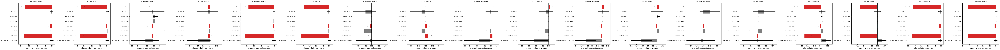

In [5]:
# Figure: change in balanced accuracy for every perturbation (bars = bootstrap 95% interval, trial sampling only)
combos = [(s, c, sd) for s in SUBJECTS for c in CONDITIONS for sd in SEEDS]
fig, axes = plt.subplots(1, len(combos), figsize=(5.2 * len(combos), 4.8), squeeze=False)
for ax, (sid, cond, seed) in zip(axes[0], combos):
    g = df1[(df1.subject == sid) & (df1.condition == cond) & (df1.seed == seed)].reset_index(drop=True)
    colors = ['tab:red' if p == 'target' else 'tab:gray' for p in g.perturbation]
    ax.barh(range(len(g)), g['delta'], color=colors, xerr=[g['delta'] - g['ci_low'], g['ci_high'] - g['delta']], capsize=2)
    ax.set_yticks(range(len(g))); ax.set_yticklabels([f"{b}: {p}" for b, p in zip(g.band, g.perturbation)], fontsize=7)
    ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis()
    ax.set_xlabel('Change in balanced accuracy'); ax.set_title(f'A{sid:02d} {cond} (seed {seed})', fontsize=9)
plt.tight_layout(); plt.savefig(OUT / 'analysis1_frequency_perturbation.png', dpi=200); plt.show()

## 2b. Analysis 1, variant B -band removed before the baseline normalisation (added after inspecting variant A)

**This variant was added after the results of variant A had been seen and is declared as a post-hoc addition.** Reason: in variant A the band is removed from the already-normalised window only, while the normalisation statistics come from the *unperturbed* pre-cue baseline. Removing mu from the window alone lowers the window amplitude relative to the baseline in every trial and every class, which looks to the model like a very strong, class-independent ERD. A drop in accuracy (and a collapse of the predictions onto one class, see `max_pred_class_share`) can therefore reflect this artificial shift rather than loss of class-specific information.

In variant B the band is removed from the cleaned data of the **baseline and the window together** (the 1 s before the cue plus the 0.5-3.5 s window, as one segment per trial), and the result is then normalised exactly as in the main experiment (mean and standard deviation of the pre-cue baseline of the perturbed segment). The unperturbed version of this pipeline must reproduce the original test windows (asserted). Both variants are reported side by side; neither replaces the other, and the reading rule and the controls are identical.

variant B without perturbation reproduces the original test windows for all participants


c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Ski

,subject,condition,seed,band,perturbation,removed_hz,variance_removed,ba_original,ba_perturbed,delta,ci_low,ci_high,max_pred_class_share
0,1,NoAug,0,mu,target,4.0,0.127,0.6840,0.3403,-0.3438,-0.3877,-0.2948,0.566
1,1,NoAug,0,mu,ctrl_2-6,4.0,0.253,0.6840,0.6493,-0.0347,-0.0750,0.0041,0.358
2,1,NoAug,0,mu,ctrl_32-36,4.0,0.018,0.6840,0.6875,0.0035,-0.0070,0.0153,0.309
3,1,NoAug,0,mu,ctrl_36-40,4.0,0.011,0.6840,0.6875,0.0035,-0.0077,0.0155,0.312
4,1,NoAug,0,beta,target,17.1,0.164,0.6840,0.6979,0.0139,-0.0164,0.0442,0.330
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,9,Aug,0,mu,ctrl_36-40,4.0,0.002,0.6875,0.6875,0.0000,0.0000,0.0000,0.302
140,9,Aug,0,beta,target,17.1,0.088,0.6875,0.6771,-0.0104,-0.0298,0.0091,0.306
141,9,Aug,0,beta,ctrl_2-8+31-40,15.1,0.322,0.6875,0.6979,0.0104,-0.0327,0.0491,0.299
142,9,Aug,0,mu+beta,target,22.0,0.518,0.6875,0.2708,-0.4167,-0.4650,-0.3663,0.837


,subject,condition,seed,band,delta_target,worst_control_delta,exceeds_all_controls,target_ci_excludes_zero,max_pred_class_share_target
0,1,Aug,0,beta,0.0243,-0.0243,False,False,0.326
1,1,Aug,0,mu,-0.3403,-0.0278,True,True,0.569
2,1,Aug,0,mu+beta,-0.3472,-0.0590,True,True,0.573
3,1,NoAug,0,beta,0.0139,-0.0278,False,False,0.330
4,1,NoAug,0,mu,-0.3438,-0.0347,True,True,0.566
5,1,NoAug,0,mu+beta,-0.3542,-0.0660,True,True,0.562
6,2,Aug,0,beta,0.0069,-0.0208,False,False,0.368
7,2,Aug,0,mu,-0.0174,-0.0278,False,True,0.434
8,2,Aug,0,mu+beta,-0.0069,-0.0347,False,False,0.389
9,2,NoAug,0,beta,0.0104,-0.0139,False,False,0.361


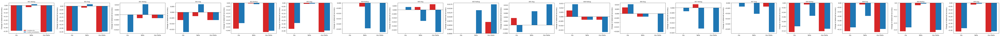

In [6]:
def windows_band_removed_before_normalisation(sid, spans):
    '''Variant B: remove the band from baseline + window of the CLEANED data, then baseline-normalise as in load_session.'''
    p = session_paths(sid, 'E')
    table = read_trial_table(p)
    eeg, _, _ = read_clean_eeg(p['fif'])
    meta = DATA[sid][2]
    assert meta['kept'].all(), 'variant B assumes that no trial was excluded'
    start_off = int(round(CFG['mi_start_after_cue_s'] * FS)); n_samp = CFG['n_samples']
    b0, b1 = int(round(CFG['baseline_start_s'] * FS)), int(round(CFG['baseline_end_s'] * FS))
    seg = np.stack([eeg[:, c + b0:c + start_off + n_samp] for c in table['cue_sample'].values])        # (trials, 22, baseline+window)
    var_removed, width = 0.0, 0.0
    if spans:
        seg_p, width, var_removed = remove_band(seg, spans)
        seg = seg_p.astype(np.float64)
    base = seg[:, :, :b1 - b0]
    win = seg[:, :, start_off - b0:start_off - b0 + n_samp]
    X = (win - base.mean(axis=-1, keepdims=True)) / (base.std(axis=-1, keepdims=True) + 1e-8)
    return X.astype(np.float32), width, var_removed

# the unperturbed variant-B pipeline must reproduce the windows used by the main experiment
for sid in SUBJECTS:
    Xb0, _, _ = windows_band_removed_before_normalisation(sid, [])
    assert np.allclose(Xb0, DATA[sid][0], atol=1e-4), f'A{sid:02d}: variant B pipeline does not reproduce the original windows'
print('variant B without perturbation reproduces the original test windows for all participants')

rows1b = []
for sid in SUBJECTS:
    _, y, _ = DATA[sid]
    cache = {}
    for band, spans in BANDS.items():
        for name, sp in [('target', spans)] + list(CONTROLS[band].items()):
            cache[(band, name)] = (windows_band_removed_before_normalisation(sid, sp), sp)
    for cond in CONDITIONS:
        for seed in SEEDS:
            model, rid = load_model(sid, cond, seed)
            p0 = predict_labels(model, DATA[sid][0]); ba0 = bal_acc(y, p0)
            for (band, name), ((Xp, width, var_removed), sp) in cache.items():
                p1 = predict_labels(model, Xp)
                lo, hi = boot_delta(y, p0, p1)
                r = dict(subject=sid, condition=cond, seed=seed, band=band, perturbation=name, removed_hz=round(width, 1),
                         variance_removed=round(var_removed, 3), ba_original=round(ba0, 4), ba_perturbed=round(bal_acc(y, p1), 4),
                         delta=round(bal_acc(y, p1) - ba0, 4), ci_low=round(lo, 4), ci_high=round(hi, 4),
                         max_pred_class_share=round(float(np.bincount(p1, minlength=4).max() / len(p1)), 3))
                r.update({f'recall_delta_{n}': round(float(a - b), 3) for n, a, b in
                          zip(CFG['class_names'], per_class_recall(y, p1), per_class_recall(y, p0))})
                rows1b.append(r)
df1b = pd.DataFrame(rows1b)
flags_b = []
for (sid, cond, seed, band), g in df1b.groupby(['subject', 'condition', 'seed', 'band']):
    t = g[g.perturbation == 'target'].iloc[0]; c = g[g.perturbation != 'target']
    flags_b.append(dict(subject=sid, condition=cond, seed=seed, band=band, delta_target=t['delta'], worst_control_delta=c['delta'].min(),
                        exceeds_all_controls=bool((t['delta'] < c['delta']).all()), target_ci_excludes_zero=bool(t['ci_high'] < 0),
                        max_pred_class_share_target=t['max_pred_class_share']))
df1b_flags = pd.DataFrame(flags_b)
df1b.to_csv(OUT / 'analysis1b_frequency_perturbation_before_normalisation.csv', index=False)
df1b_flags.to_csv(OUT / 'analysis1b_reading_rule.csv', index=False)
display(df1b.drop(columns=[c for c in df1b.columns if c.startswith('recall_delta_')]))
display(df1b_flags)

# side-by-side figure: variant A (window only) vs variant B (before normalisation), target bands only
fig, axes = plt.subplots(1, len(combos), figsize=(5.2 * len(combos), 3.6), squeeze=False)
for ax, (sid, cond, seed) in zip(axes[0], combos):
    a = df1[(df1.subject == sid) & (df1.condition == cond) & (df1.seed == seed) & (df1.perturbation == 'target')].set_index('band')
    b = df1b[(df1b.subject == sid) & (df1b.condition == cond) & (df1b.seed == seed) & (df1b.perturbation == 'target')].set_index('band')
    xs = np.arange(len(BANDS)); w = 0.38
    ax.bar(xs - w / 2, [a.loc[k, 'delta'] for k in BANDS], w, label='A: window only', color='tab:red')
    ax.bar(xs + w / 2, [b.loc[k, 'delta'] for k in BANDS], w, label='B: before normalisation', color='tab:blue')
    ax.set_xticks(xs); ax.set_xticklabels(list(BANDS)); ax.axhline(0, color='k', lw=0.8)
    ax.set_ylabel('Change in balanced accuracy'); ax.set_title(f'A{sid:02d} {cond}', fontsize=9)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.savefig(OUT / 'analysis1b_variants_comparison.png', dpi=200); plt.show()

## 3. Analysis 2  channel occlusion

Channels are occluded by replacing them with 0, i.e. the value of their own pre-cue baseline mean in normalised units. Targets: C3, Cz and C4 together and one at a time, and all 17 sensorimotor channels. Controls: every triple of the 5 non-sensorimotor channels (exhaustive, 10 triples), random triples drawn from all other channels, and random 17-channel subsets. The percentile reports where the target drop falls among the random subsets of the same size (fraction of random subsets whose drop is **at least as large** as the target's). For the sensorimotor group only 5 non-sensorimotor channels exist, so the anatomical control is smaller than the target.

In [7]:
SM17 = ['FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4']
CORE3 = ['C3', 'Cz', 'C4']
NON_SM = [c for c in CH if c not in SM17]
assert len(SM17) == 17 and len(NON_SM) == 5 and set(CORE3) <= set(SM17)
def occlude(X3, chans):
    Xo = X3.copy(); Xo[:, [ix[c] for c in chans], :] = 0.0
    return Xo

def random_subsets(size, exclude, n, rng):
    out = set()
    while len(out) < n:                                   # sample without replacement, never the target itself
        s = tuple(sorted(rng.choice(CH, size=size, replace=False)))
        if set(s) != set(exclude):
            out.add(s)
    return list(out)

rng2 = np.random.default_rng(RNG_SEED + 1)
SUBSETS = {'core3': random_subsets(3, CORE3, N_RANDOM_SUBSETS, rng2), 'sm17': random_subsets(17, SM17, N_RANDOM_SUBSETS, rng2)}
ANATOMICAL3 = list(itertools.combinations(NON_SM, 3))

rows2, null_rows = [], []
for sid in SUBJECTS:
    X3, y, _ = DATA[sid]
    for cond in CONDITIONS:
        for seed in SEEDS:
            model, rid = load_model(sid, cond, seed)
            p0 = predict_labels(model, X3); ba0 = bal_acc(y, p0); rec0 = per_class_recall(y, p0)
            def run(chans):
                p1 = predict_labels(model, occlude(X3, chans)); return p1, bal_acc(y, p1) - ba0
            targets = {'core3(C3,Cz,C4)': CORE3, 'C3 only': ['C3'], 'Cz only': ['Cz'], 'C4 only': ['C4'],
                       'sm17(all sensorimotor)': SM17, 'non-sensorimotor(5)': NON_SM}
            deltas = {}
            for name, chans in targets.items():
                p1, d = run(chans); lo, hi = boot_delta(y, p0, p1); deltas[name] = d
                r = dict(subject=sid, condition=cond, seed=seed, occluded=name, n_channels=len(chans), ba_original=round(ba0, 4),
                         delta=round(d, 4), ci_low=round(lo, 4), ci_high=round(hi, 4),
                         max_pred_class_share=round(float(np.bincount(p1, minlength=4).max() / len(p1)), 3))
                r.update({f'recall_delta_{n}': round(float(a - b), 3) for n, a, b in zip(CFG['class_names'], per_class_recall(y, p1), rec0)})
                rows2.append(r)
            anat = [run(list(t))[1] for t in ANATOMICAL3]                       # all triples of non-sensorimotor channels
            null3 = [run(list(t))[1] for t in SUBSETS['core3']]
            null17 = [run(list(t))[1] for t in SUBSETS['sm17']]
            null_rows.append(dict(subject=sid, condition=cond, seed=seed,
                                  core3_delta=round(deltas['core3(C3,Cz,C4)'], 4),
                                  anatomical_controls_delta_min_median_max=(round(min(anat), 4), round(float(np.median(anat)), 4), round(max(anat), 4)),
                                  core3_frac_random_subsets_at_least_as_damaging=round(float(np.mean(np.array(null3) <= deltas['core3(C3,Cz,C4)'])), 3),
                                  sm17_delta=round(deltas['sm17(all sensorimotor)'], 4),
                                  sm17_frac_random_subsets_at_least_as_damaging=round(float(np.mean(np.array(null17) <= deltas['sm17(all sensorimotor)'])), 3)))
df2, df2_null = pd.DataFrame(rows2), pd.DataFrame(null_rows)
df2.to_csv(OUT / 'analysis2_channel_occlusion.csv', index=False); df2_null.to_csv(OUT / 'analysis2_vs_controls.csv', index=False)
display(df2.drop(columns=[c for c in df2.columns if c.startswith('recall_delta_')]))
print('Target vs control channel groups (fraction of random subsets of equal size that are at least as damaging):')
display(df2_null)
print('Per-class recall change when C3, Cz or C4 is occluded alone (descriptive):')
display(df2[df2.occluded.isin(['C3 only', 'Cz only', 'C4 only'])][['subject', 'condition', 'occluded'] + [c for c in df2.columns if c.startswith('recall_delta_')]])

c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
c:\Users\ACER\anaconda3\envs\env_master_2025\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Ski

,subject,condition,seed,occluded,n_channels,ba_original,delta,ci_low,ci_high,max_pred_class_share
0,1,NoAug,0,"core3(C3,Cz,C4)",3,0.6840,-0.1562,-0.2190,-0.0919,0.472
1,1,NoAug,0,C3 only,1,0.6840,-0.0382,-0.0862,0.0088,0.358
2,1,NoAug,0,Cz only,1,0.6840,-0.0729,-0.1207,-0.0257,0.358
3,1,NoAug,0,C4 only,1,0.6840,-0.1076,-0.1642,-0.0483,0.479
4,1,NoAug,0,sm17(all sensorimotor),17,0.6840,-0.4583,-0.5170,-0.3967,0.660
...,...,...,...,...,...,...,...,...,...,...
103,9,Aug,0,C3 only,1,0.6875,-0.1111,-0.1546,-0.0668,0.389
104,9,Aug,0,Cz only,1,0.6875,-0.0486,-0.0996,0.0032,0.438
105,9,Aug,0,C4 only,1,0.6875,-0.2188,-0.2809,-0.1521,0.573
106,9,Aug,0,sm17(all sensorimotor),17,0.6875,-0.4340,-0.4884,-0.3809,0.906


Target vs control channel groups (fraction of random subsets of equal size that are at least as damaging):


,subject,condition,seed,core3_delta,anatomical_controls_delta_min_median_max,core3_frac_random_subsets_at_least_as_damaging,sm17_delta,sm17_frac_random_subsets_at_least_as_damaging
0,1,NoAug,0,-0.1562,"(-0.191, -0.0521, -0.0278)",0.385,-0.4583,0.005
1,1,Aug,0,-0.1389,"(-0.1632, -0.0434, -0.0139)",0.465,-0.4514,0.010
2,2,NoAug,0,-0.1389,"(-0.1562, -0.1128, -0.0556)",0.330,-0.1944,0.445
3,2,Aug,0,-0.1354,"(-0.1632, -0.1163, -0.0521)",0.370,-0.2014,0.425
4,3,NoAug,0,-0.2257,"(-0.2882, -0.1667, -0.0243)",0.430,-0.5208,0.290
5,3,Aug,0,-0.2465,"(-0.25, -0.1545, -0.0312)",0.340,-0.5243,0.255
6,4,NoAug,0,-0.0625,"(-0.1146, -0.0868, -0.0486)",0.760,-0.1771,0.535
7,4,Aug,0,-0.0556,"(-0.1146, -0.0851, -0.0382)",0.765,-0.1701,0.520
8,5,NoAug,0,-0.0521,"(-0.1285, -0.0747, -0.0347)",0.615,-0.1285,0.640
9,5,Aug,0,-0.0451,"(-0.1285, -0.0799, -0.0486)",0.745,-0.1250,0.715


Per-class recall change when C3, Cz or C4 is occluded alone (descriptive):


,subject,condition,occluded,recall_delta_left hand,recall_delta_right hand,recall_delta_feet,recall_delta_tongue
1,1,NoAug,C3 only,0.097,-0.222,0.000,-0.028
2,1,NoAug,Cz only,-0.181,-0.056,-0.069,0.014
3,1,NoAug,C4 only,-0.069,-0.222,-0.306,0.167
7,1,Aug,C3 only,0.111,-0.222,0.014,-0.042
8,1,Aug,Cz only,-0.153,-0.069,-0.069,0.014
9,1,Aug,C4 only,-0.083,-0.194,-0.292,0.167
13,2,NoAug,C3 only,-0.042,-0.250,0.125,-0.208
14,2,NoAug,Cz only,-0.181,0.069,-0.125,-0.097
15,2,NoAug,C4 only,-0.125,-0.069,0.111,-0.250
19,2,Aug,C3 only,-0.056,-0.250,0.125,-0.208


## 4. Analysis 3 - ERD/ERS per class (independent of the model)

Band power is computed from the cleaned data (not from model inputs): band-pass (4th-order Butterworth, zero-phase, applied run by run), squared Hilbert envelope, epoched from 1 s before to 3.5 s after the cue. ERD/ERS (%) = (power − reference) / reference × 100 with the reference being the mean power in the 1 s before the cue (the same baseline used for normalisation), averaged over trials of each class; negative values mean ERD. The same analysis is run on session `T` (training data) and session `E` (test data) so that the stability of the effect across sessions can be seen. Labels are used only to group trials; nothing here feeds the model. Zero-phase filtering and the Hilbert envelope are non-causal on purpose, because this is a descriptive analysis.

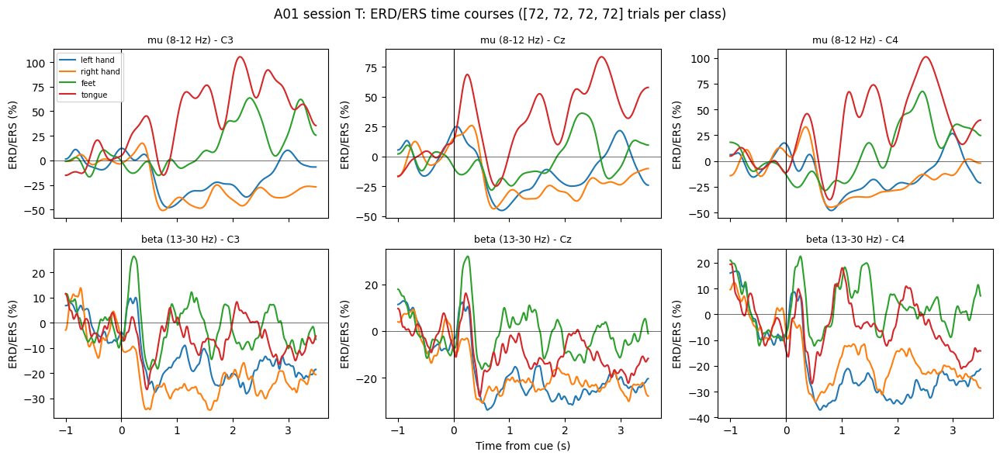

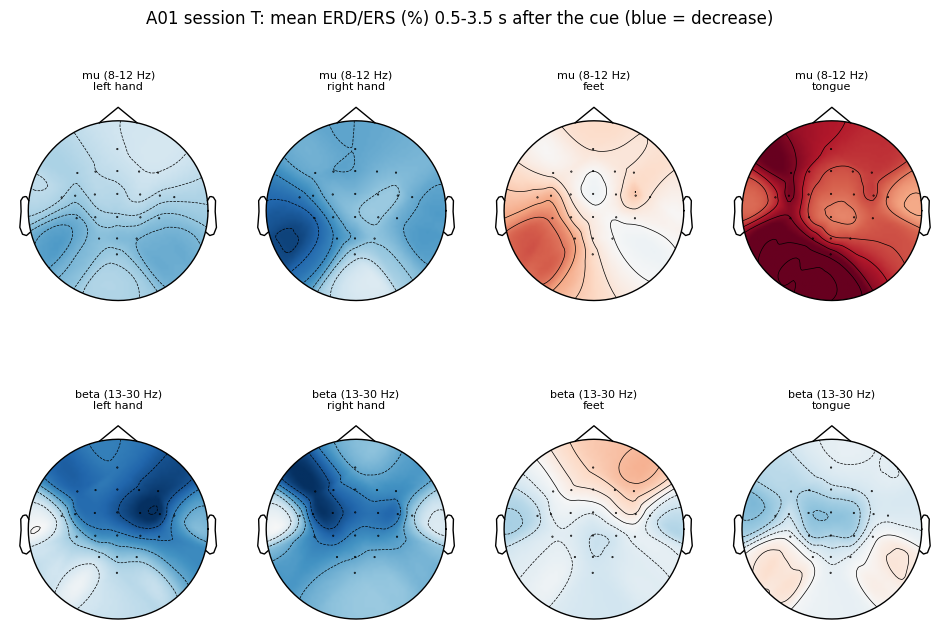

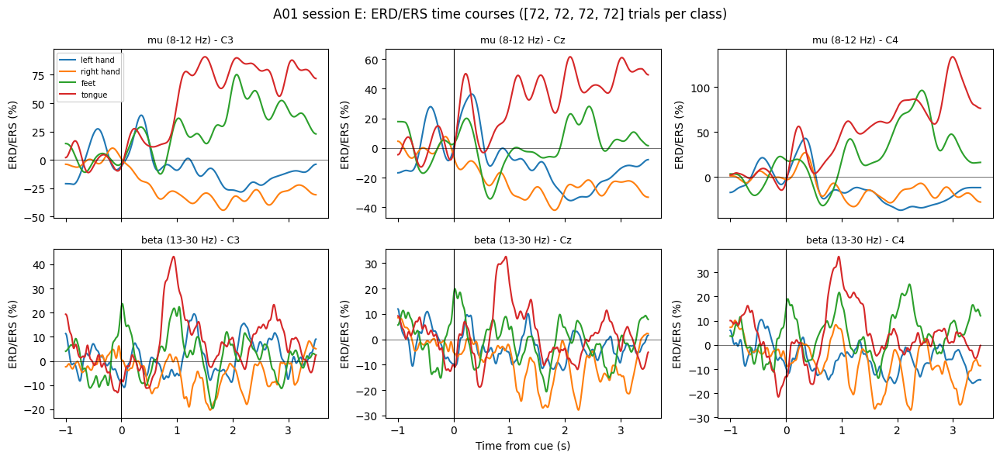

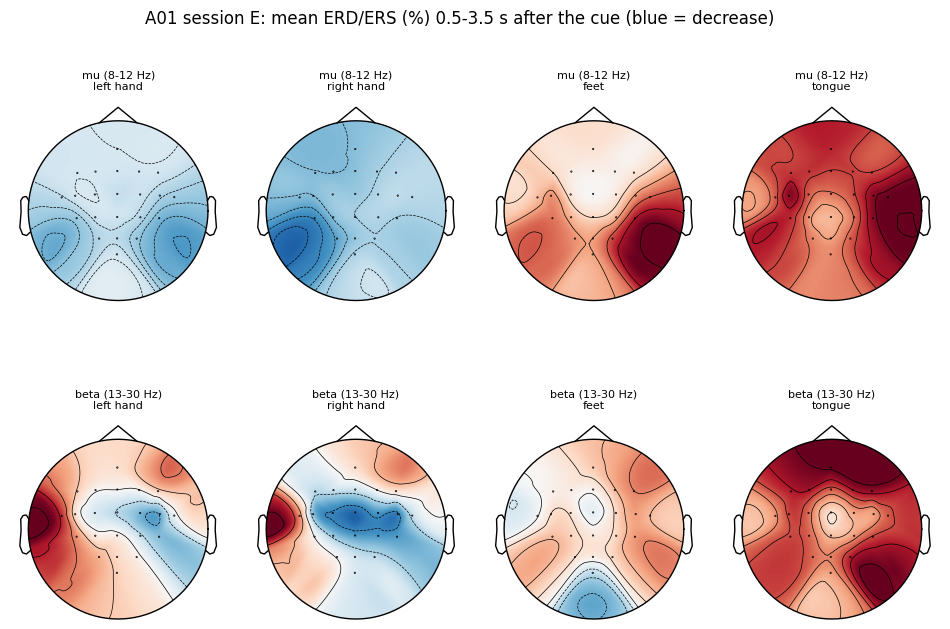

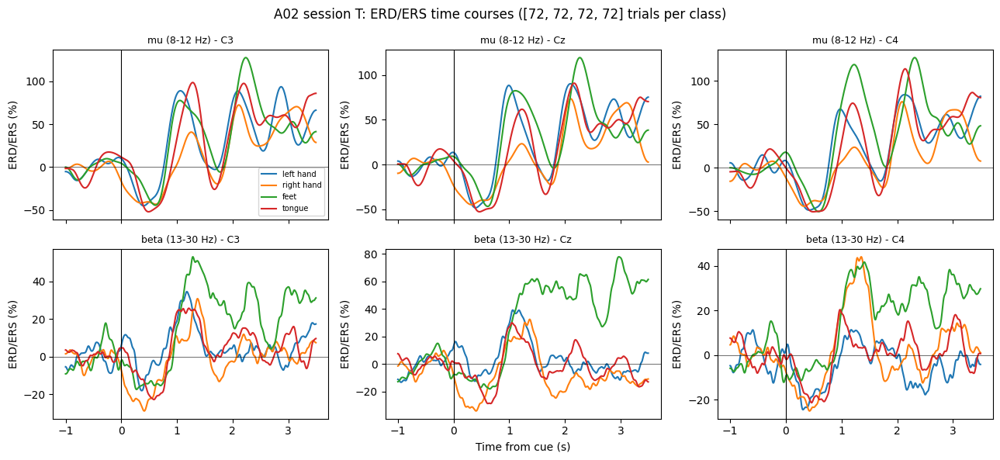

...

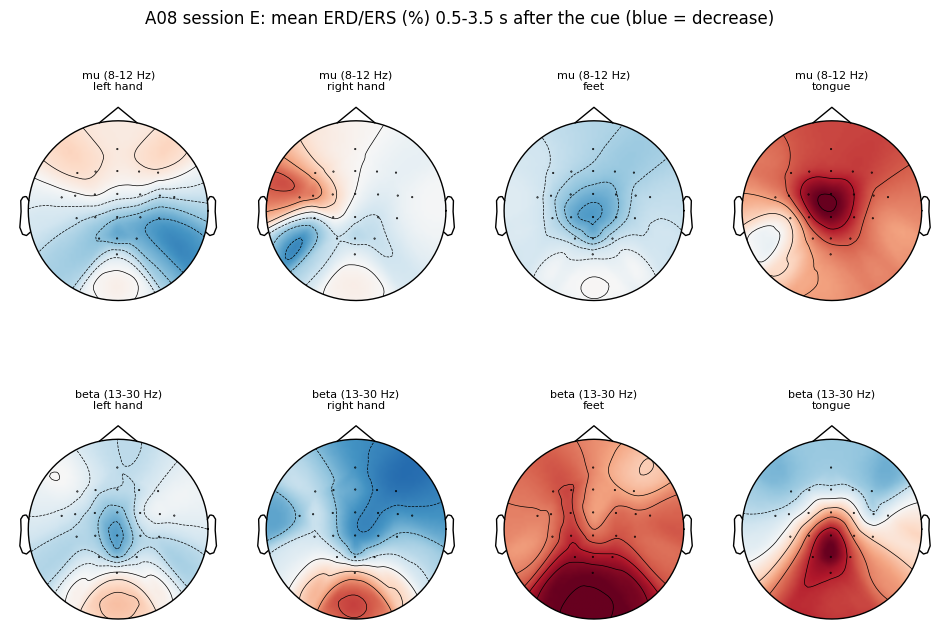

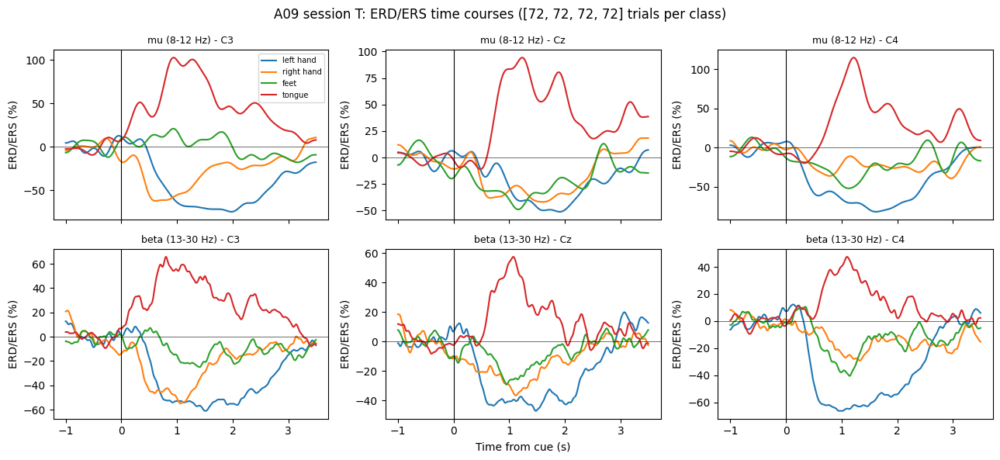

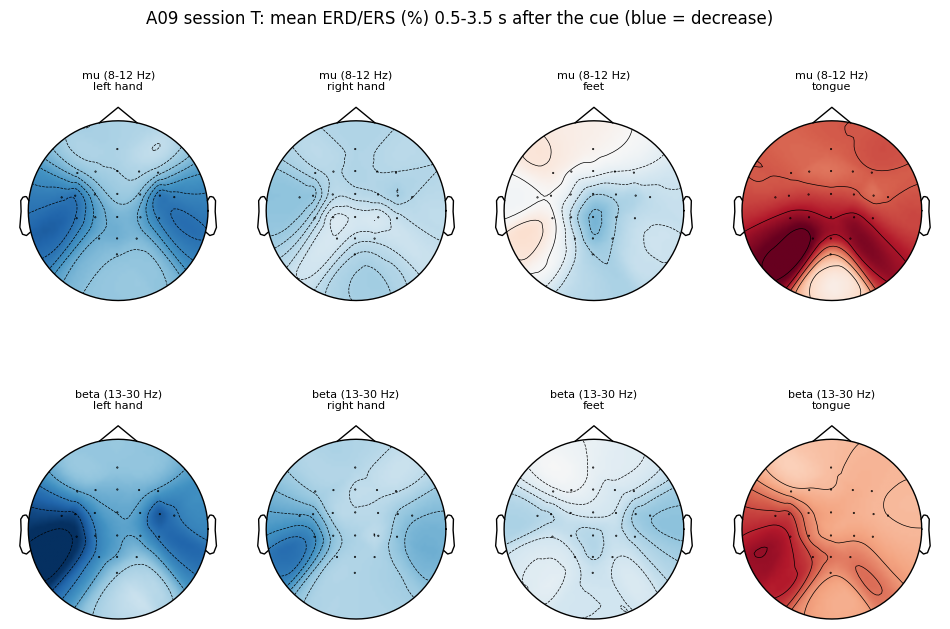

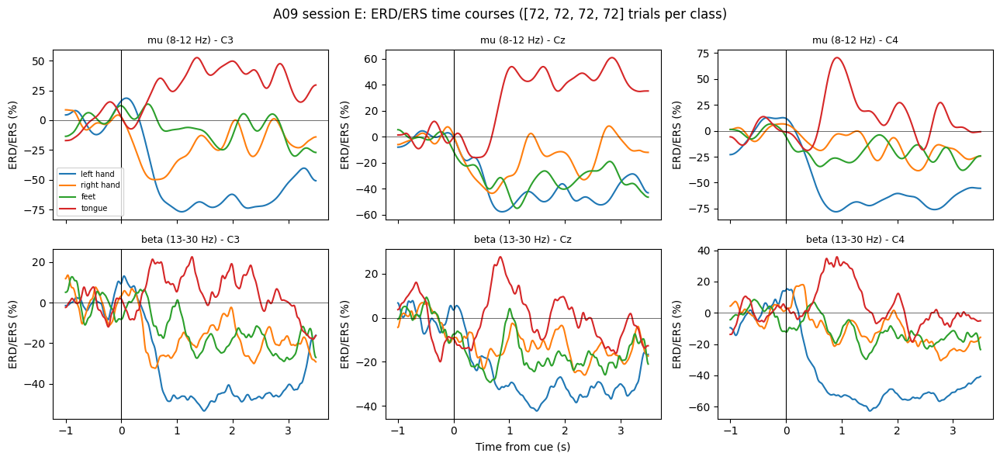

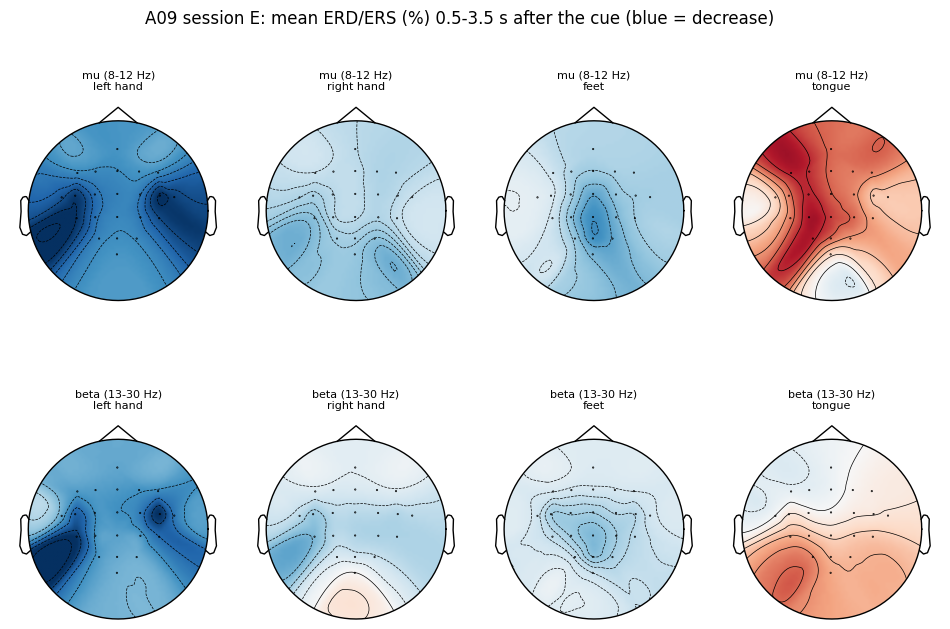

Mean ERD/ERS (%) in the classification window. Contra - ipsi < 0 means stronger decrease on the contralateral side.


,subject,session,band,left_hand_C3,left_hand_C4,right_hand_C3,right_hand_C4,feet_Cz,tongue_Cz,left_contra_minus_ipsi,right_contra_minus_ipsi
0,1,T,mu (8-12 Hz),-22.3,-17.3,-37.1,-23.6,-2.5,34.9,5.0,-13.4
1,1,T,beta (13-30 Hz),-19.1,-28.8,-25.2,-21.3,-2.6,-11.7,-9.7,-3.9
2,1,E,mu (8-12 Hz),-13.4,-22.5,-32.1,-18.8,0.8,38.7,-9.1,-13.3
3,1,E,beta (13-30 Hz),2.3,-7.8,-6.5,-10.5,-1.4,2.5,-10.1,4.0
4,2,T,mu (8-12 Hz),41.8,36.4,24.2,19.3,41.8,30.0,-5.3,4.9
5,2,T,beta (13-30 Hz),7.2,-3.9,2.5,6.0,43.0,-1.2,-11.1,-3.5
6,2,E,mu (8-12 Hz),23.5,23.1,12.5,19.9,27.9,8.1,-0.3,-7.4
7,2,E,beta (13-30 Hz),6.0,2.8,-3.3,-1.0,13.0,2.6,-3.2,-2.3
8,3,T,mu (8-12 Hz),-36.1,-36.8,-58.3,-20.0,-9.9,24.7,-0.7,-38.3
9,3,T,beta (13-30 Hz),-1.2,2.3,-5.7,1.5,-1.1,2.9,3.5,-7.2


In [8]:
ERD_BANDS = {'mu (8-12 Hz)': (8, 12), 'beta (13-30 Hz)': (13, 30)}
PRE, POST = int(1.0 * FS), int(3.5 * FS)                  # samples before / after the cue
T_AX = np.arange(-PRE, POST) / FS
WIN = slice(PRE + int(0.5 * FS), PRE + int(3.5 * FS))     # the classification window (0.5-3.5 s after the cue)

def erd_session(sid, session):
    p = session_paths(sid, session)
    table = read_trial_table(p)
    eeg, _, _ = read_clean_eeg(p['fif'])                  # (22, n) volts, cleaned
    res = {}
    for bname, (lo, hi) in ERD_BANDS.items():
        sos = butter(4, [lo, hi], btype='bandpass', fs=FS, output='sos')
        env = np.zeros_like(eeg)
        for rs, re_ in table[['run_start_sample', 'run_end_sample']].drop_duplicates().values:   # filter run by run
            env[:, rs:re_] = np.abs(hilbert(sosfiltfilt(sos, eeg[:, rs:re_], axis=-1), axis=-1)) ** 2
        P = np.stack([env[:, c - PRE:c + POST] for c in table['cue_sample'].values])             # (trials, 22, time)
        assert (table['cue_sample'] + POST <= table['run_end_sample']).all() and (table['cue_sample'] - PRE >= table['run_start_sample']).all()
        labels = table['label'].values
        base = P[:, :, :PRE].mean(axis=2)
        curves, windows = {}, {}
        for c in range(4):
            sel = labels == c
            R = base[sel].mean(axis=0)
            A = P[sel].mean(axis=0)
            curves[c] = uniform_filter1d(100 * (A - R[:, None]) / R[:, None], size=int(0.25 * FS), axis=-1)
            windows[c] = 100 * (A[:, WIN].mean(axis=1) - R) / R
        res[bname] = dict(curves=curves, window=windows, n_per_class=[int((labels == c).sum()) for c in range(4)])
    return res

ERD = {(sid, ses): erd_session(sid, ses) for sid in SUBJECTS for ses in ['T', 'E']}
info = mne.create_info(CH, FS, 'eeg'); info.set_montage(mne.channels.make_standard_montage('standard_1020'))
for (sid, ses), res in ERD.items():
    # (a) time courses at C3 / Cz / C4
    fig, axes = plt.subplots(len(ERD_BANDS), 3, figsize=(13, 6), sharex=True, squeeze=False)
    for i, bname in enumerate(ERD_BANDS):
        for j, ch in enumerate(['C3', 'Cz', 'C4']):
            for c in range(4):
                axes[i, j].plot(T_AX, res[bname]['curves'][c][ix[ch]], label=CFG['class_names'][c])
            axes[i, j].axvline(0, color='k', lw=0.8); axes[i, j].axhline(0, color='k', lw=0.4)
            axes[i, j].set_title(f'{bname} - {ch}', fontsize=9); axes[i, j].set_ylabel('ERD/ERS (%)')
    axes[-1, 1].set_xlabel('Time from cue (s)'); axes[0, 0].legend(fontsize=7)
    fig.suptitle(f'A{sid:02d} session {ses}: ERD/ERS time courses ({res[list(ERD_BANDS)[0]]["n_per_class"]} trials per class)')
    plt.tight_layout(); plt.savefig(OUT / f'analysis3_erd_timecourse_A{sid:02d}{ses}.png', dpi=170); plt.show()
    # (b) scalp maps of the mean ERD/ERS in the classification window
    fig, axes = plt.subplots(len(ERD_BANDS), 4, figsize=(12, 7.2), squeeze=False)
    for i, bname in enumerate(ERD_BANDS):
        vmax = max(np.abs(res[bname]['window'][c]).max() for c in range(4))
        for c in range(4):
            im, _ = mne.viz.plot_topomap(res[bname]['window'][c], info, axes=axes[i, c], show=False, cmap='RdBu_r', vlim=(-vmax, vmax))
            axes[i, c].set_title(f'{bname}\n{CFG["class_names"][c]}', fontsize=8)
    fig.suptitle(f'A{sid:02d} session {ses}: mean ERD/ERS (%) 0.5-3.5 s after the cue (blue = decrease)')
    fig.subplots_adjust(top=0.88, hspace=0.35, wspace=0.1); plt.savefig(OUT / f'analysis3_erd_topomap_A{sid:02d}{ses}.png', dpi=170); plt.show()

# summary table: contralateral vs ipsilateral ERD for the hand classes (left hand -> C4 contralateral, right hand -> C3)
rows3 = []
for (sid, ses), res in ERD.items():
    for bname in ERD_BANDS:
        w = res[bname]['window']
        rows3.append(dict(subject=sid, session=ses, band=bname,
                          left_hand_C3=round(w[0][ix['C3']], 1), left_hand_C4=round(w[0][ix['C4']], 1),
                          right_hand_C3=round(w[1][ix['C3']], 1), right_hand_C4=round(w[1][ix['C4']], 1),
                          feet_Cz=round(w[2][ix['Cz']], 1), tongue_Cz=round(w[3][ix['Cz']], 1),
                          left_contra_minus_ipsi=round(w[0][ix['C4']] - w[0][ix['C3']], 1),
                          right_contra_minus_ipsi=round(w[1][ix['C3']] - w[1][ix['C4']], 1)))
df3 = pd.DataFrame(rows3); df3.to_csv(OUT / 'analysis3_erd_summary.csv', index=False)
print('Mean ERD/ERS (%) in the classification window. Contra - ipsi < 0 means stronger decrease on the contralateral side.')
display(df3)

## 5. Analysis 4 class-by-class comparison

For each frozen model, the per-class recall and the confusion matrix on session `E` are shown next to the ERD of the same participant (analysis 3, session `E`). Hand classes are compared with their **contralateral** channel (left hand → C4, right hand → C3); feet and tongue are shown at Cz only for reference, with no channel pre-specified for the tongue. The table also reports how often the two hand classes are confused with each other, which is what a lateralisation account would predict to be low when the contralateral ERD is clear. This is a side-by-side description: with 4 classes per participant it does not support a correlation or a test, and it does not establish that the model uses the ERD.

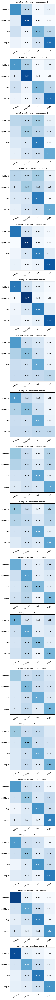

,subject,condition,seed,recall_left,recall_right,recall_feet,recall_tongue,left_to_right_share,right_to_left_share,hands_vs_nonhands_share,ERD_E_mu_left_at_C4,ERD_E_mu_right_at_C3,ERD_E_beta_left_at_C4,ERD_E_beta_right_at_C3,ERD_E_mu_feet_at_Cz,ERD_E_beta_feet_at_Cz
0,1,NoAug,0,0.625,0.889,0.472,0.750,0.292,0.111,0.042,-22.5,-32.1,-7.8,-6.5,0.8,-1.4
1,1,Aug,0,0.597,0.889,0.472,0.750,0.319,0.111,0.042,-22.5,-32.1,-7.8,-6.5,0.8,-1.4
2,2,NoAug,0,0.278,0.361,0.708,0.514,0.292,0.194,0.438,23.1,12.5,2.8,-3.3,27.9,13.0
3,2,Aug,0,0.292,0.361,0.708,0.514,0.278,0.194,0.438,23.1,12.5,2.8,-3.3,27.9,13.0
4,3,NoAug,0,0.736,0.972,0.694,0.847,0.181,0.000,0.056,-48.3,-63.3,-6.3,-12.1,-0.2,8.1
5,3,Aug,0,0.722,0.972,0.694,0.833,0.194,0.000,0.056,-48.3,-63.3,-6.3,-12.1,-0.2,8.1
6,4,NoAug,0,0.583,0.431,0.514,0.278,0.222,0.319,0.222,-9.6,-9.5,-8.0,-21.3,36.8,9.8
7,4,Aug,0,0.569,0.431,0.514,0.264,0.236,0.319,0.222,-9.6,-9.5,-8.0,-21.3,36.8,9.8
8,5,NoAug,0,0.389,0.264,0.542,0.528,0.236,0.306,0.403,-9.3,3.9,-3.6,-2.1,-3.0,-5.1
9,5,Aug,0,0.389,0.264,0.542,0.542,0.236,0.306,0.403,-9.3,3.9,-3.6,-2.1,-3.0,-5.1


In [9]:
rows4 = []
fig, axes = plt.subplots(len(SUBJECTS) * len(CONDITIONS), len(SEEDS), figsize=(4.2 * len(SEEDS), 3.8 * len(SUBJECTS) * len(CONDITIONS)), squeeze=False)
k = 0
for sid in SUBJECTS:
    _, y, me = DATA[sid]
    for cond in CONDITIONS:
        for seed in SEEDS:
            rid = f'A{sid:02d}_{cond}_seed{seed}'
            pr = pd.read_csv(RESULTS_DIR / 'predictions' / f'{rid}.csv')
            yt, yp = pr['true_label'].values, pr['pred_label'].values
            cm = np.array([[((yt == a) & (yp == b)).sum() for b in range(4)] for a in range(4)]); cmn = cm / cm.sum(axis=1, keepdims=True)
            rec = np.diag(cmn)
            w_mu, w_be = ERD[(sid, 'E')]['mu (8-12 Hz)']['window'], ERD[(sid, 'E')]['beta (13-30 Hz)']['window']
            rows4.append(dict(subject=sid, condition=cond, seed=seed,
                              recall_left=round(rec[0], 3), recall_right=round(rec[1], 3), recall_feet=round(rec[2], 3), recall_tongue=round(rec[3], 3),
                              left_to_right_share=round(cmn[0, 1], 3), right_to_left_share=round(cmn[1, 0], 3),
                              hands_vs_nonhands_share=round((cm[0, 2:].sum() + cm[1, 2:].sum()) / (cm[0].sum() + cm[1].sum()), 3),
                              ERD_E_mu_left_at_C4=round(w_mu[0][ix['C4']], 1), ERD_E_mu_right_at_C3=round(w_mu[1][ix['C3']], 1),
                              ERD_E_beta_left_at_C4=round(w_be[0][ix['C4']], 1), ERD_E_beta_right_at_C3=round(w_be[1][ix['C3']], 1),
                              ERD_E_mu_feet_at_Cz=round(w_mu[2][ix['Cz']], 1), ERD_E_beta_feet_at_Cz=round(w_be[2][ix['Cz']], 1)))
            ax = axes[k, 0] if len(SEEDS) == 1 else axes[k // len(SEEDS), k % len(SEEDS)]
            ax.imshow(cmn, vmin=0, vmax=1, cmap='Blues')
            for a in range(4):
                for b in range(4):
                    ax.text(b, a, f'{cmn[a, b]:.2f}', ha='center', va='center', color='white' if cmn[a, b] > 0.5 else 'black', fontsize=8)
            ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(CFG['class_names'], rotation=30, fontsize=7); ax.set_yticklabels(CFG['class_names'], fontsize=7)
            ax.set_title(f'A{sid:02d} {cond} (row-normalised, session E)', fontsize=8); k += 1
plt.tight_layout(); plt.savefig(OUT / 'analysis4_confusions.png', dpi=180); plt.show()
df4 = pd.DataFrame(rows4); df4.to_csv(OUT / 'analysis4_class_by_class.csv', index=False)
display(df4)

##  Conclusions
 Test balanced accuracy was heterogeneous: 0.43–0.81, mean 0.561 for both conditions. Paired Aug − NoAug differences were within ±0.011 for every participant. The interpretability outputs of the two conditions are nearly identical, so with this augmentation ($\sigma = 0.05, p = 0.5$) neither accuracy nor the frequencies and channels the models rely on changed in a way these analyses can detect.

| Participant | Test bal. acc. (NoAug / Aug) | $\Delta$ bal. acc. removing mu (variant B, NoAug) | $\Delta$ removing beta (variant B, NoAug) |
| :--- | :---: | :---: | :---: |
| **A01** | 0.684 / 0.677 | −0.344 | +0.014 |
| **A02** | 0.465 / 0.469 | −0.017 | +0.010 |
| **A03** | 0.813 / 0.806 | −0.295 | −0.017 |
| **A04** | 0.451 / 0.444 | 0.000 | −0.024 |
| **A05** | 0.431 / 0.434 | 0.000 | +0.014 |
| **A06** | 0.493 / 0.493 | +0.014 | −0.004 |
| **A07** | 0.455 / 0.458 | −0.004 | −0.021 |
| **A08** | 0.569 / 0.580 | −0.101 | −0.056 |
| **A09** | 0.688 / 0.688 | −0.365 | −0.010 |

---

### Q1. Does the model depend on mu/beta, more than on control frequencies?

- **Mu (8–12 Hz):** **Yes** for 4 of 9 participants. In A01, A03, A08, and A09, removing mu lowers balanced accuracy by 0.10–0.37, with a bootstrap interval excluding 0 and a larger drop than every width-matched control. This holds in both variants and in both conditions. For the other five participants (A02, A04–A07) the change is $\le 0.017$ in absolute value.
- The four participants with mu dependence are the four with the highest accuracy (0.57–0.81); the five without are all $\le 0.49$ (Spearman $\rho = -0.78$ between accuracy and the mu-removal drop, $n = 9$, descriptive only).
- **Beta (13–30 Hz):** **Not established.** Removing beta alone has no clear effect in 8 of 9 participants in variant B; A08 is the exception (−0.056, interval excluding 0). The combined band costs more than mu alone in A03 (about −0.40 vs −0.29), so a contribution of beta cannot be excluded, but it is not shown.
- **Limit: distribution shift.** Under mu removal, predictions concentrate on one class in several participants (variant B, share of the most frequent class: A09 0.73–0.76, A03 0.51–0.59, A01 0.57), so part of the drop can reflect an input shift rather than selective loss of class information. These analyses show dependence on 8–12 Hz content, not that the model decodes ERD/ERS dynamics.
- **Participants without mu/beta dependence.** Removing the complementary range (1.5–7.9 and 30.1–40 Hz) costs up to about 0.05–0.06 in some of them (e.g., A06, A04, A05), small and without intervals in the saved tables. These models may rely on other content (slow components, residual muscle or ocular activity); this was not investigated.

---

### Q2. Does the decision depend on the expected scalp areas?

- **Not specifically.** Removing C3/Cz/C4 together is more damaging than almost all random channel triples only in A09 (fraction of random triples at least as damaging 0.005–0.015). In the other eight participants that fraction is 0.33–0.77. In eight of nine participants the worst triple of non-sensorimotor channels (Fz, P1, Pz, P2, POz) is as damaging as, or more damaging than, C3/Cz/C4.
- All 17 sensorimotor channels stand out against random subsets in A01 (fraction 0.005–0.010) and weakly in A09 (0.085), not in the others.
- **Single channels.** Occluding Cz lowers feet recall by $\ge 0.17$ in six participants (A03–A08), the most consistent anatomical result. A contralateral pattern is only partial: occluding C3 lowers right-hand recall by $\ge 0.10$ in 4 of 9 (A01, A02, A03, A07), and occluding C4 lowers left-hand recall by $\ge 0.10$ in 4 of 9 (A02–A05), with several opposite or non-selective cases.
- Parietal/frontal channels also carry information the models use; EEG channels mix sources, so this does not identify the origin.

---

### Q3. Do the data contain the expected ERD/ERS effect?

- **Partly and unevenly.** Mu ERD in the hand classes is clear in A01, A03, and A09, bilateral and strong in A07 (but similar in all classes, hence not discriminative), weak in A04–A05, and absent or reversed in A02 and A06. Beta ERD is weak almost everywhere.
- **Contralateral lateralisation is a weak tendency.** The expected sign ($\text{contra} - \text{ipsi} < 0$) appears in 26 of 36 participant $\times$ session $\times$ hand cells for mu and 27 of 36 for beta, with a mean $\text{contra} - \text{ipsi}$ of about −6 (mu) and −4 (beta) percentage points; it is present in all four cells only for A03 and A04. A08 shows an opposite right-hand pattern.
- Tongue imagery shows a mu increase at Cz in 7 of 9 participants in both sessions.
- The effects are reasonably stable between sessions T and E in the participants with strong ERD (A01, A03, A09), and unstable in A06 and A08.

---

### Q4. Are the confusion patterns compatible with lateralisation?

- **Only in part.** In A01 and A03 the right hand, with a clear contralateral ERD at C3, has the highest recall (0.89 and 0.97), and the left hand, with bilateral ERD, is the one confused with the other hand. In A09 recall is highest for the left hand (0.93) whose ERD is strong but bilateral, so the model seems to follow the ERD magnitude rather than its lateralisation. In A08 the tongue (largest mu increase at Cz, +74%) has the highest recall.
- Left right confusion remains 7–32% even in the best participants, and the participants with the lowest accuracy are those with weak, absent, or class-independent ERD.

---

### Overall Answer

For the participants for whom the model works well (A01, A03, A09, to a lesser extent A08), the decision depends on 8–12 Hz content, in line with sensorimotor mu ERD/ERS. This is not shown for beta, not specific to sensorimotor channels, and not shown for the five participants with accuracy $\le 0.49$. We cannot claim that EEGNet "decodes mu rhythms" in general.

---

### Limitations

Exploratory analyses; one seed; nine heterogeneous participants; trial-level bootstrap intervals do not cover variability across sessions or participants; band removal also changes signal scale and creates inputs the model never saw (variant B, added post hoc, reduces but does not remove this); beta may contain muscle activity; the reasons for the low accuracy of five participants were not investigated.